# Multi-Layer Fully Connected Network
In this exercise, you will implement a fully connected network with an arbitrary number of hidden layers.

Read through the `FullyConnectedNet` class in the file `cm2003/classifiers/fc_net.py`.

Implement the network initialization, forward pass, and backward pass. Please read through and understand the layers implementations in: `cm2003/layers.py`. 


In [1]:
# Setup cell.
import time
import numpy as np
import matplotlib.pyplot as plt
from cm2003.classifiers.fc_net import *
from cm2003.data_utils import get_CIFAR10_data
from cm2003.gradient_check import eval_numerical_gradient, eval_numerical_gradient_array
from cm2003.solver import Solver

%matplotlib inline
plt.rcParams["figure.figsize"] = (10.0, 8.0)  # Set default size of plots.
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gray"

%load_ext autoreload
%autoreload 2

def rel_error(x, y):
    """Returns relative error."""
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

In [2]:
# Get the datasets (CIFAR-10 and PneumoniaMNIST). Does nothing if they are already there.
%run download_data.py

CIFAR-10 is already there: C:\Users\Admin\Documents\GitHub\Lab-2\cm2003\datasets\cifar-10-batches-py
PneumoniaMNIST is already there: C:\Users\Admin\Documents\GitHub\Lab-2\cm2003\datasets\pneumoniamnist.npz


In [3]:
# Load the (preprocessed) CIFAR-10 data.
data = get_CIFAR10_data()
for k, v in list(data.items()):
    print(f"{k}: {v.shape}")

X_train: (49000, 3, 32, 32)
y_train: (49000,)
X_val: (1000, 3, 32, 32)
y_val: (1000,)
X_test: (1000, 3, 32, 32)
y_test: (1000,)


## Initial Loss and Gradient Check

As a sanity check, run the following to check the initial loss and to gradient check the network both with and without regularization. This is a good way to see if the initial losses seem reasonable.

For gradient checking, you should expect to see errors around 1e-7 or less.

In [5]:
np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=(N,))

for reg in [0, 3.14]:
    print("Running check with reg = ", reg)
    model = FullyConnectedNet(
        [H1, H2],
        input_dim=D,
        num_classes=C,
        reg=reg,
        weight_scale=5e-2,
        dtype=np.float64
    )

    loss, grads = model.loss(X, y)
    print("Initial loss: ", loss)

    # Most of the errors should be on the order of e-7 or smaller.   
    # NOTE: It is fine however to see an error for W2 on the order of e-5
    # for the check when reg = 0.0
    for name in sorted(grads):
        f = lambda _: model.loss(X, y)[0]
        grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
        print(f"{name} relative error: {rel_error(grad_num, grads[name])}")

Running check with reg =  0
Initial loss:  2.300479089768492
W1 relative error: 1.0252674471656573e-07
W2 relative error: 2.2120479295080622e-05
W3 relative error: 4.5623278736665505e-07
b1 relative error: 4.6600944653202505e-09
b2 relative error: 2.085654276112763e-09
b3 relative error: 1.689724888469736e-10
Running check with reg =  3.14
Initial loss:  7.052114776533016
W1 relative error: 1.409028728052923e-08
W2 relative error: 6.86942277940646e-08
W3 relative error: 2.131129859578198e-08
b1 relative error: 1.4752427965311745e-08
b2 relative error: 1.7223751746766738e-09
b3 relative error: 2.378772438198909e-10


As another sanity check, make sure your network can overfit on a small dataset of 50 images. First, we will try a three-layer network with 100 units in each hidden layer. In the following cell, tweak the **learning rate** and **weight initialization scale** to overfit and achieve 100% training accuracy within 20 epochs.

(Iteration 1 / 40) loss: 5.496252
(Epoch 0 / 20) train acc: 0.280000; val_acc: 0.119000
(Epoch 1 / 20) train acc: 0.380000; val_acc: 0.149000
(Epoch 2 / 20) train acc: 0.480000; val_acc: 0.157000
(Epoch 3 / 20) train acc: 0.720000; val_acc: 0.148000
(Epoch 4 / 20) train acc: 0.740000; val_acc: 0.161000
(Epoch 5 / 20) train acc: 0.780000; val_acc: 0.155000
(Iteration 11 / 40) loss: 0.369655
(Epoch 6 / 20) train acc: 0.820000; val_acc: 0.158000
(Epoch 7 / 20) train acc: 0.760000; val_acc: 0.165000
(Epoch 8 / 20) train acc: 0.940000; val_acc: 0.153000
(Epoch 9 / 20) train acc: 0.960000; val_acc: 0.157000
(Epoch 10 / 20) train acc: 0.960000; val_acc: 0.150000
(Iteration 21 / 40) loss: 0.140958
(Epoch 11 / 20) train acc: 0.980000; val_acc: 0.144000
(Epoch 12 / 20) train acc: 1.000000; val_acc: 0.149000
(Epoch 13 / 20) train acc: 1.000000; val_acc: 0.150000
(Epoch 14 / 20) train acc: 1.000000; val_acc: 0.147000
(Epoch 15 / 20) train acc: 1.000000; val_acc: 0.152000
(Iteration 31 / 40) loss: 

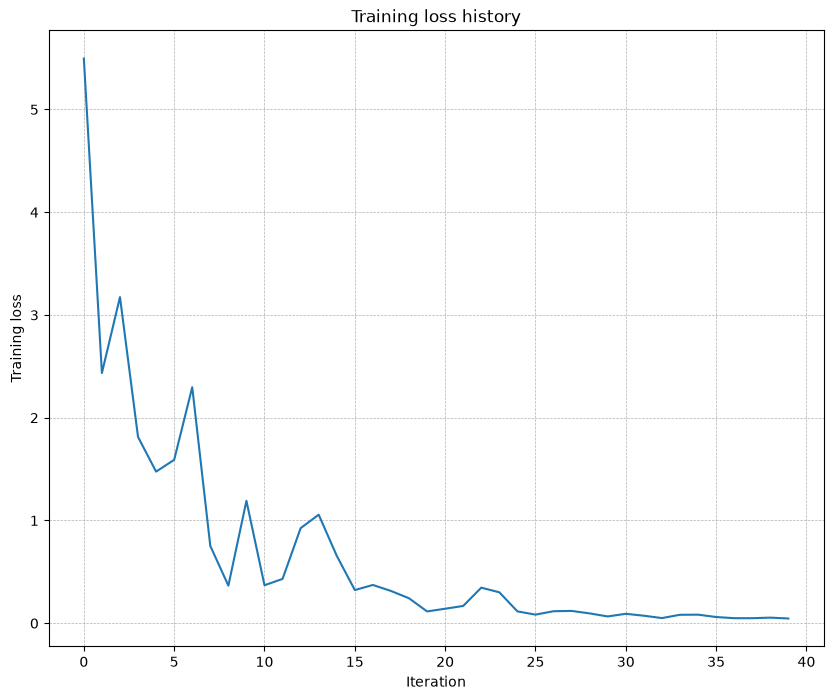

In [8]:
# TODO: Use a three-layer Net to overfit 50 training examples by 
# tweaking just the learning rate and initialization scale.

num_train = 50
small_data = {
  "X_train": data["X_train"][:num_train],
  "y_train": data["y_train"][:num_train],
  "X_val": data["X_val"],
  "y_val": data["y_val"],
}

weight_scale = 3e-2   # Experiment with this!
learning_rate = 8e-4  # Experiment with this!
model = FullyConnectedNet(
    [100, 100],
    weight_scale=weight_scale,
    dtype=np.float64
)
solver = Solver(
    model,
    small_data,
    print_every=10,
    num_epochs=20,
    batch_size=25,
    update_rule="sgd",
    optim_config={"learning_rate": learning_rate},
)
solver.train()

plt.plot(solver.loss_history)
plt.title("Training loss history")
plt.xlabel("Iteration")
plt.ylabel("Training loss")
plt.grid(linestyle='--', linewidth=0.5)
plt.show()

Now, try to use a five-layer network with 100 units on each layer to overfit on 50 training examples. Again, you will have to adjust the learning rate and weight initialization scale, but you should be able to achieve 100% training accuracy within 20 epochs.

(Iteration 1 / 40) loss: 93.437542
(Epoch 0 / 20) train acc: 0.160000; val_acc: 0.112000
(Epoch 1 / 20) train acc: 0.160000; val_acc: 0.088000
(Epoch 2 / 20) train acc: 0.220000; val_acc: 0.093000
(Epoch 3 / 20) train acc: 0.420000; val_acc: 0.136000
(Epoch 4 / 20) train acc: 0.440000; val_acc: 0.100000
(Epoch 5 / 20) train acc: 0.440000; val_acc: 0.104000
(Iteration 11 / 40) loss: 3.330759
(Epoch 6 / 20) train acc: 0.620000; val_acc: 0.093000
(Epoch 7 / 20) train acc: 0.880000; val_acc: 0.117000
(Epoch 8 / 20) train acc: 0.900000; val_acc: 0.118000
(Epoch 9 / 20) train acc: 0.920000; val_acc: 0.111000
(Epoch 10 / 20) train acc: 0.980000; val_acc: 0.120000
(Iteration 21 / 40) loss: 0.164140
(Epoch 11 / 20) train acc: 0.980000; val_acc: 0.115000
(Epoch 12 / 20) train acc: 0.980000; val_acc: 0.112000
(Epoch 13 / 20) train acc: 1.000000; val_acc: 0.109000
(Epoch 14 / 20) train acc: 1.000000; val_acc: 0.112000
(Epoch 15 / 20) train acc: 1.000000; val_acc: 0.111000
(Iteration 31 / 40) loss:

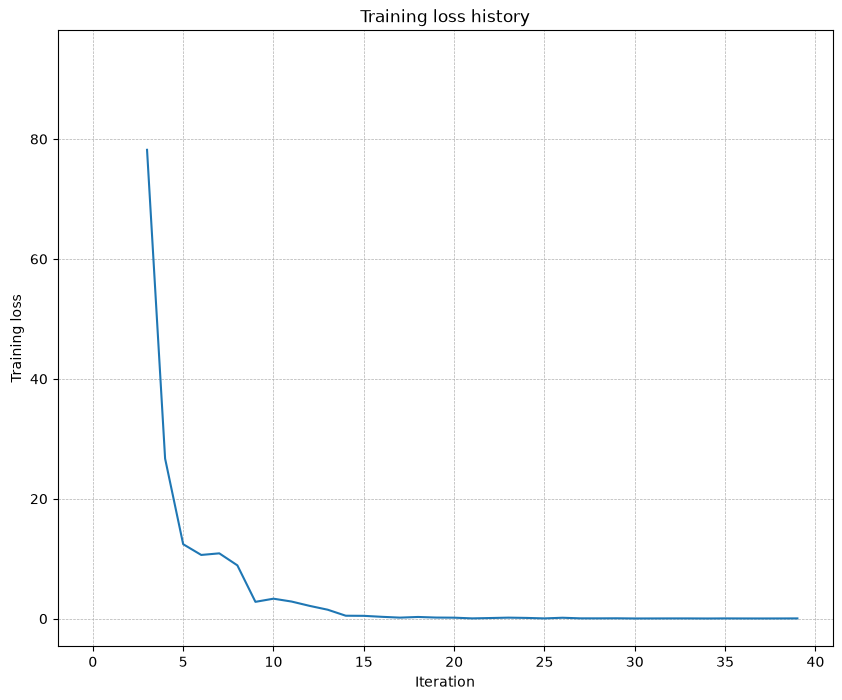

In [22]:
# TODO: Use a five-layer Net to overfit 50 training examples by 
# tweaking just the learning rate and initialization scale.

num_train = 50
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

learning_rate = 3e-3  # Experiment with this!
weight_scale = 1e-1   # Experiment with this!
model = FullyConnectedNet(
    [100, 100, 100, 100],
    weight_scale=weight_scale,
    dtype=np.float64
)
solver = Solver(
    model,
    small_data,
    print_every=10,
    num_epochs=20,
    batch_size=25,
    update_rule='sgd',
    optim_config={'learning_rate': learning_rate},
)
solver.train()

plt.plot(solver.loss_history)
plt.title('Training loss history')
plt.xlabel('Iteration')
plt.ylabel('Training loss')
plt.grid(linestyle='--', linewidth=0.5)
plt.show()

## Inline Question 1: 
Did you notice anything about the comparative difficulty of training the three-layer network vs. training the five-layer network? In particular, based on your experience, which network seemed more sensitive to the initialization scale? Why do you think that is the case?

## Answer:
[FILL THIS IN]


## SGD+Momentum
Stochastic gradient descent with momentum is a widely used update rule that tends to make deep networks converge faster than vanilla stochastic gradient descent. See the Momentum Update section at http://cs231n.github.io/neural-networks-3/#sgd for more information.

Open the file `cm2003/optim.py` and read the documentation at the top of the file to make sure you understand the API. Implement the SGD+momentum update rule in the function `sgd_momentum` and run the following to check your implementation. You should see errors less than e-8.

In [ ]:
from cm2003.optim import sgd_momentum

N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
v = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)

config = {"learning_rate": 1e-3, "velocity": v}
next_w, _ = sgd_momentum(w, dw, config=config)

expected_next_w = np.asarray([
  [ 0.1406,      0.20738947,  0.27417895,  0.34096842,  0.40775789],
  [ 0.47454737,  0.54133684,  0.60812632,  0.67491579,  0.74170526],
  [ 0.80849474,  0.87528421,  0.94207368,  1.00886316,  1.07565263],
  [ 1.14244211,  1.20923158,  1.27602105,  1.34281053,  1.4096    ]])
expected_velocity = np.asarray([
  [ 0.5406,      0.55475789,  0.56891579, 0.58307368,  0.59723158],
  [ 0.61138947,  0.62554737,  0.63970526,  0.65386316,  0.66802105],
  [ 0.68217895,  0.69633684,  0.71049474,  0.72465263,  0.73881053],
  [ 0.75296842,  0.76712632,  0.78128421,  0.79544211,  0.8096    ]])

# Should see relative errors around e-8 or less
print("next_w error: ", rel_error(next_w, expected_next_w))
print("velocity error: ", rel_error(expected_velocity, config["velocity"]))

Once you have done so, run the following to train a six-layer network with both SGD and SGD+momentum. You should see the SGD+momentum update rule converge faster.

In [ ]:
num_train = 4000
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

solvers = {}

for update_rule in ['sgd', 'sgd_momentum']:
    print('Running with ', update_rule)
    model = FullyConnectedNet(
        [100, 100, 100, 100, 100],
        weight_scale=5e-2
    )

    solver = Solver(
        model,
        small_data,
        num_epochs=5,
        batch_size=100,
        update_rule=update_rule,
        optim_config={'learning_rate': 5e-3},
        verbose=True,
    )
    solvers[update_rule] = solver
    solver.train()

fig, axes = plt.subplots(3, 1, figsize=(15, 15))

axes[0].set_title('Training loss')
axes[0].set_xlabel('Iteration')
axes[1].set_title('Training accuracy')
axes[1].set_xlabel('Epoch')
axes[2].set_title('Validation accuracy')
axes[2].set_xlabel('Epoch')

for update_rule, solver in solvers.items():
    axes[0].plot(solver.loss_history, label=f"loss_{update_rule}")
    axes[1].plot(solver.train_acc_history, label=f"train_acc_{update_rule}")
    axes[2].plot(solver.val_acc_history, label=f"val_acc_{update_rule}")
    
for ax in axes:
    ax.legend(loc="best", ncol=4)
    ax.grid(linestyle='--', linewidth=0.5)

plt.show()

## Adam Optimizer

Adam (Adaptive Moment Estimation) is an advanced optimization algorithm that combines ideas from RMSprop and momentum methods. It's widely used in deep learning due to its efficiency and good performance across a wide range of problems.

### Update Rule

The Adam update rule can be summarized as follows:
```python
m = beta1 m + (1 - beta1) dx
v = beta2 v + (1 - beta2) (dx2)
m_hat = m / (1 - beta1t)
v_hat = v / (1 - beta2t)
x += - learning_rate m_hat / (np.sqrt(v_hat) + epsilon)

```

Where:
- `m` and `v` are moving averages of the gradient and squared gradient
- `beta1` and `beta2` are decay rates for these moving averages (typically 0.9 and 0.999)
- `t` is the time step
- `epsilon` is a small value to prevent division by zero (typically 1e-8)

### Comparison to SGD

1. **Adaptive learning rates**: Unlike SGD, Adam adapts the learning rate for each parameter based on the historical gradients, allowing it to handle different scales of parameters more effectively.

2. **Momentum**: Adam incorporates a form of momentum similar to SGD, which helps accelerate convergence in relevant directions and dampen oscillations.

3. **Bias correction**: Adam includes bias correction terms to counteract the initialization bias of the moving averages.

4. **Robustness**: Adam is often more robust to hyperparameter choices than SGD, making it easier to find good default values.

5. **Computational cost**: Adam requires more memory and computation per update than SGD, but this is often offset by faster convergence.

In practice, Adam often converges faster and finds better optima than SGD. When using PyTorch, you can use the `torch.optim.Adam` optimizer as default for most cases.
